All required classes and functions:

In [72]:
from __future__ import annotations
import cmath
import matplotlib.pyplot as plt
import numpy as np
import random
from scipy import fft

class PeakParams:
    def __init__(self,
        amplitude: float|int,
        frequency: float|int,
        encoded_frequency: float|int = None,
        relaxation_time: float|int = None,
        ):
        self.amplitude = amplitude
        self.frequency = frequency
        self.encoded_frequency = encoded_frequency
        self.relaxation_time = relaxation_time

class DimensionParams:
    def __init__(self,
        spectral_width: float|int,
        points: int,
        irradiation_time: float|int = None,
        irradiation_B1_strength: float|int = None,
        ):
        self.spectral_width = spectral_width
        self.points = points
        self.irradiation_time = irradiation_time
        self.irradiation_B1_strength = irradiation_B1_strength


def calculate_time_axis(
    points: int, 
    spectral_width: float|int,
    ) -> list[float]:
    time_axis = [i/spectral_width for i in range(points)]
    return time_axis


def calculate_frequency_axis(
    points: int,
    spectral_width: float|int,
    ) -> np.array[float]:
    frequency_axis = np.fft.fftfreq(points, d=1/spectral_width)
    frequency_axis = fft.fftshift(frequency_axis)
    return frequency_axis


def simulate_fid(
    dimension: DimensionParams,
    *peaks: PeakParams,
    irradiated_dimension: DimensionParams = None,
    zero_filling: int = 1,
    noise_factor: float|int = 0,
    ) -> tuple[list[float], list[complex]]:
    points = dimension.points
    sw = dimension.spectral_width
    time_axis = []
    fid = []
    if irradiated_dimension:
        irr_sw = irradiated_dimension.spectral_width
        irr_time = irradiated_dimension.irradiation_time
        irr_B1 = irradiated_dimension.irradiation_B1_strength
    
    for i in range(points):
        fid_intensity = 0
        t = i/sw
        time_axis.append(t)

        if irradiated_dimension:
            ni_irr_i = -irr_sw/2 + i*irr_sw/(points-1)

        for peak in peaks:
            A = peak.amplitude
            ni = peak.frequency
            signal_intensity = A*cmath.exp(1j*2*cmath.pi*ni*t)

            if irradiated_dimension:
                ni_encoded = peak.encoded_frequency
                delta_ni_irr = ni_encoded - ni_irr_i
                ni_eff = cmath.sqrt(irr_B1**2 + delta_ni_irr**2)
                irradiation_effect = 1 - 2*(irr_B1/ni_eff*cmath.sin(2*cmath.pi*ni_eff*irr_time/2))**2
            else:
                irradiation_effect = 1
            fid_intensity += signal_intensity * irradiation_effect + noise_factor*random.uniform(-1, 1)

        fid.append(fid_intensity)
    
    if zero_filling > 1:
        for i in range(points, zero_filling*points):
            t = i/sw
            time_axis.append(t)
            fid.append(0.0)
    return time_axis, fid


def calculate_spectrum(
    fid: list[complex], 
    dimension: DimensionParams,
    zero_filling: int = 1,
    ) -> tuple[np.array[float], np.array[complex]]:
    spectrum = fft.fft(fid)
    spectrum_points = zero_filling * len(fid)
    sw = zero_filling * dimension.spectral_width
    frequencies = calculate_frequency_axis(spectrum_points, sw)
    shifted_spectrum = fft.fftshift(spectrum)
    for i in range((spectrum_points - len(fid)) // 2):
        shifted_spectrum = np.insert(shifted_spectrum, 0, 0.0)
        shifted_spectrum = np.append(shifted_spectrum, 0.0)
    return frequencies, shifted_spectrum


def calculate_weighted_spectrum(
    spectrum: np.array[complex],
    sigma: float|int,
    fid_zero_filling: int,
    spectrum_zero_filling: int,
    ) -> tuple[np.array[complex], np.array[float]]:
    N = len(spectrum)
    sigma = sigma * len(spectrum) / spectrum_zero_filling
    x = np.arange(-N/2, N/2)
    weighting_function = np.exp(-x**2 / (2*sigma**2))
    weighted_spectrum = weighting_function * np.array(spectrum)
    return weighted_spectrum, weighting_function


def calculate_profile(
    spectrum: np.array[complex], 
    dimension: DimensionParams, 
    fid_zero_filling: int, 
    spectrum_zero_filling: int,
    ) -> tuple[list[float], np.array[complex]]:
    sw = dimension.spectral_width * spectrum_zero_filling
    points = dimension.points * fid_zero_filling * spectrum_zero_filling
    time_axis = calculate_time_axis(points, sw)
    unshifted_spectrum = fft.ifftshift(spectrum)
    profile = fft.ifft(unshifted_spectrum)
    return time_axis, profile


def get_profile_from_peaks(
    main_dimension: DimensionParams,
    irradiated_dimension: DimensionParams,
    *peaks: PeakParams,
    fid_zero_filling: int = 2,
    noise_factor: float|int = 0,
    spectrum_zero_filling: int = 2,
    sigma: float|int = 0.1,
    weighting_flag: bool = False,
    plot_flag: bool = False,
    ) -> tuple[np.array[float], np.array[complex], np.array[complex]]:
    times, fid = simulate_fid(
        main_dimension,
        *peaks,
        irradiated_dimension = irradiated_dimension,
        zero_filling = fid_zero_filling,
        noise_factor = noise_factor,
    )

    freqs, spectrum = calculate_spectrum(
        fid,
        main_dimension,
        spectrum_zero_filling,
    )
    
    if weighting_flag:
        weighted_spectrum, weighting_function = calculate_weighted_spectrum(
            spectrum,
            sigma,
            fid_zero_filling,
            spectrum_zero_filling,
        )
    else:
        weighted_spectrum = spectrum

    time_axis, profile = calculate_profile(
        weighted_spectrum,
        main_dimension,
        fid_zero_filling,
        spectrum_zero_filling,
    )

    profile_frequency_axis = calculate_frequency_axis(
        len(profile)//fid_zero_filling, irradiated_dimension.spectral_width)
    profile_relevant_part = profile[0:len(profile_frequency_axis)]
    
    if plot_flag:
        plt.figure(figsize=(10,5))
        plt.plot(profile_frequency_axis, profile_relevant_part.real, color = 'b')
        plt.xlabel('frequency [Hz]')
        plt.ylabel('intensity [arb. units]')
        plt.grid(True)
        plt.show()

    return profile_frequency_axis, profile_relevant_part, profile

Parameters:

In [73]:
peak1 = PeakParams(
    amplitude = 1,
    frequency = 0,
    encoded_frequency = -800,
    relaxation_time = 0.04,
)

peak2 = PeakParams(
    amplitude = 1, 
    frequency = 1200, 
    encoded_frequency = 360,
    relaxation_time = 0.04,
)

Ndimension = DimensionParams(
    points = 175,
    spectral_width = 5700,
)

COdimension = DimensionParams(
    points = 175,
    spectral_width = 3000,
    irradiation_time = 0.009,
    irradiation_B1_strength = 55,
)

fid_zero_filling = 5
spectrum_zero_filling = 3
sigma = 0.1
noise_factor = 0

Tests of the functions

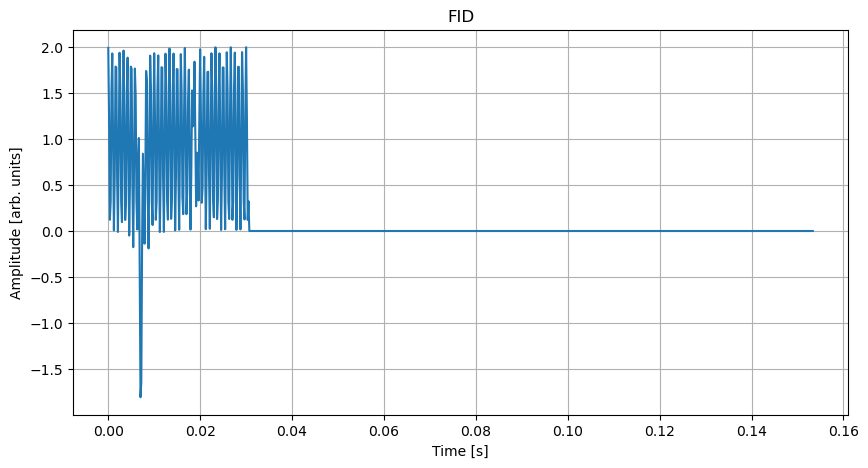

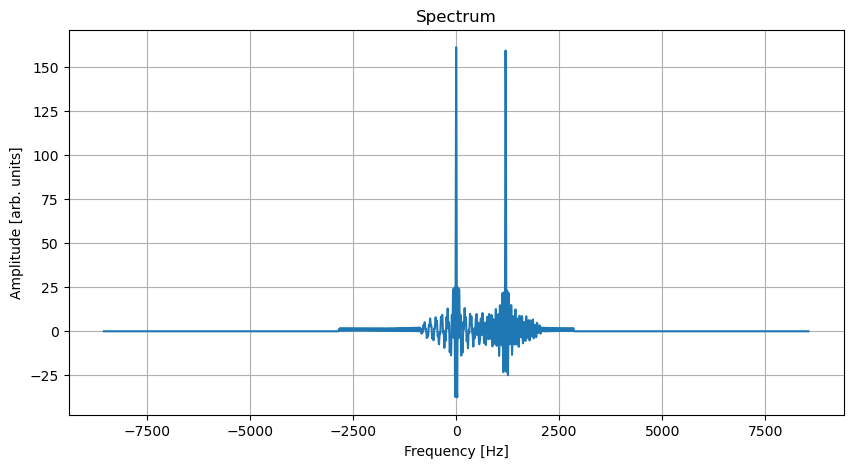

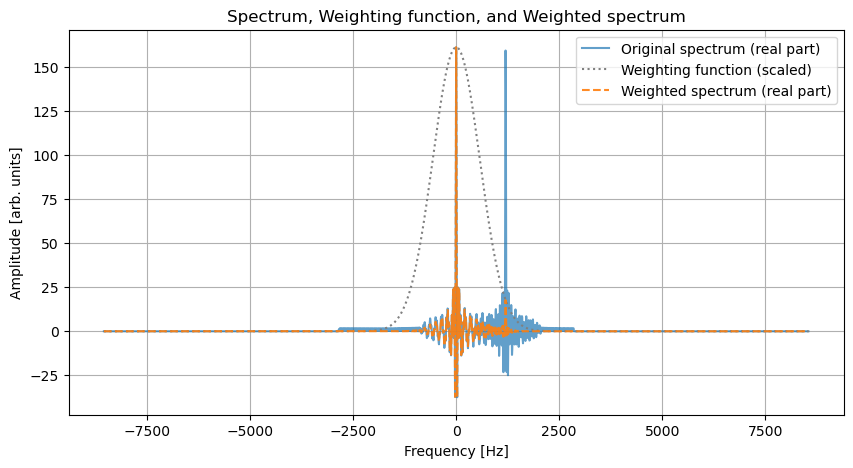

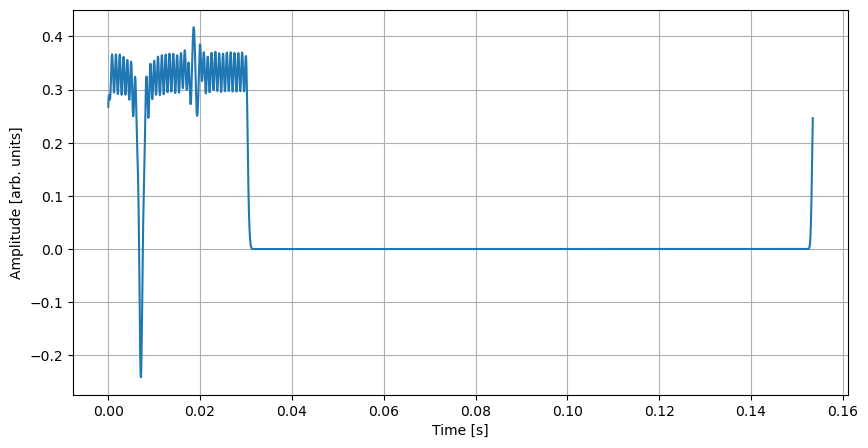

In [74]:
times, fid = simulate_fid(
    Ndimension,
    peak1, peak2,
    irradiated_dimension = COdimension,
    zero_filling = fid_zero_filling,
    noise_factor = noise_factor,
)
plt.figure(figsize=(10,5))
plt.plot(times, np.array(fid).real)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude [arb. units]')
plt.title('FID')
plt.grid(True)
plt.show()

freq, spectrum = calculate_spectrum(
    fid, 
    Ndimension, 
    zero_filling = spectrum_zero_filling
)
plt.figure(figsize=(10,5))
plt.plot(freq, np.array(spectrum).real)
plt.xlabel('Frequency [Hz]')
plt.ylabel('Amplitude [arb. units]')
plt.title('Spectrum')
plt.grid(True)
plt.show()

weighted_spectrum, weighting_function = calculate_weighted_spectrum(
    spectrum, 
    sigma, 
    fid_zero_filling,
    spectrum_zero_filling
)
plt.figure(figsize=(10, 5))
plt.plot(freq, np.array(spectrum).real, label='Original spectrum (real part)', alpha=0.7)
plt.plot(freq, weighting_function * np.max(np.array(spectrum).real), label='Weighting function (scaled)', linestyle=':', color='gray') # Scale for visibility
plt.plot(freq, np.array(weighted_spectrum).real, label='Weighted spectrum (real part)', linestyle='--', alpha=0.9)
plt.xlabel('Frequency [Hz]')
plt.ylabel('Amplitude [arb. units]')
plt.title('Spectrum, Weighting function, and Weighted spectrum')
plt.legend()
plt.grid(True)
plt.show()


time_axis, profile = calculate_profile(
    weighted_spectrum, 
    Ndimension, 
    fid_zero_filling, 
    spectrum_zero_filling)
plt.figure(figsize=(10,5))
plt.plot(time_axis, profile.real)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude [arb. units]')
plt.grid(True)
plt.show()

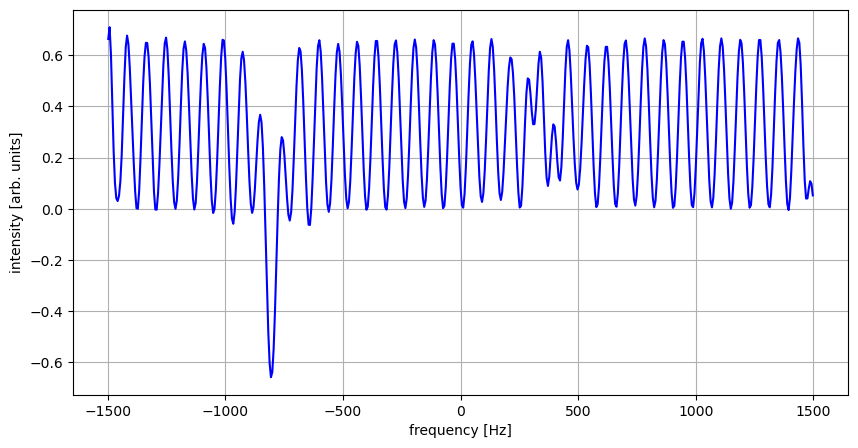

In [75]:
time_axis, profile_part, profile = get_profile_from_peaks(Ndimension, COdimension,
    peak1, peak2,
    fid_zero_filling = fid_zero_filling,
    noise_factor = noise_factor, 
    spectrum_zero_filling = spectrum_zero_filling, 
    sigma = sigma,
    plot_flag = True,
    )

Tests for two peaks

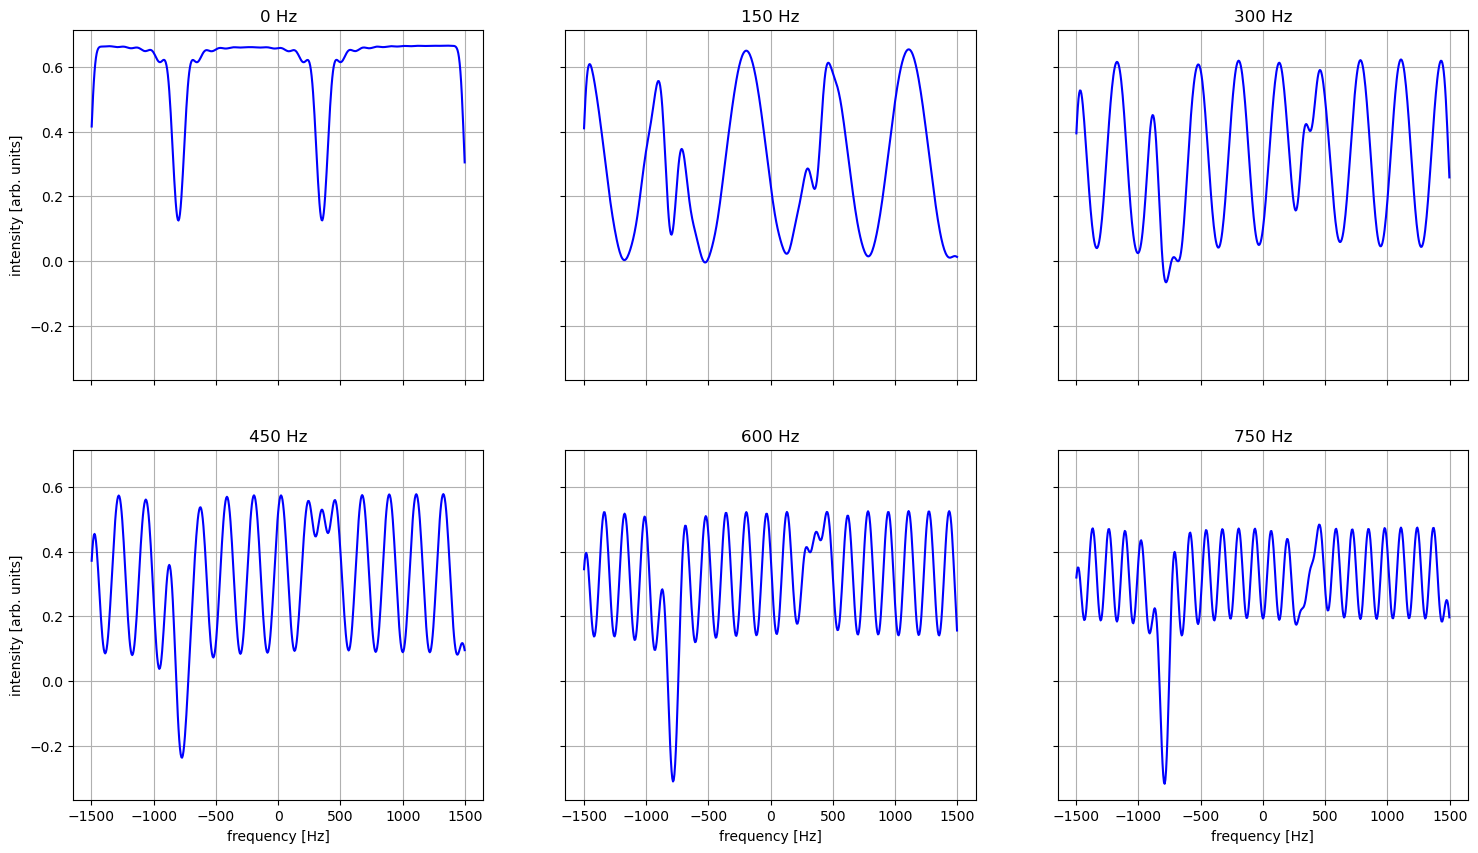

In [76]:
second_peak_frequencies = [0, 150, 300, 450, 600, 750]
fig, axes = plt.subplots(2, 3, figsize = (18, 10), sharex = True, sharey = True,)
axes = axes.flatten()

for i, frequency in enumerate(second_peak_frequencies):
    peak2 = PeakParams(
        amplitude = 1,
        frequency = frequency,
        encoded_frequency = 360,
        relaxation_time = 0.04,
    )
    time_axis, profile, profile_full = get_profile_from_peaks(Ndimension, COdimension,
        peak1, peak2,
        fid_zero_filling = fid_zero_filling,
        noise_factor = noise_factor, 
        spectrum_zero_filling = spectrum_zero_filling, 
        sigma = sigma,
        weighting_flag = True,
        plot_flag = False,
        )
    
    ax = axes[i]
    plot_label = f'{frequency} Hz'
    ax.plot(time_axis, profile.real, color='b', label=plot_label)
    ax.set_title(plot_label)
    ax.grid(True)
for i in [0, 3]:
    axes[i].set_ylabel('intensity [arb. units]')
for i in [3,4,5]:
    axes[i].set_xlabel('frequency [Hz]')
plt.show()

Influence of the irradiation field strength (with duration adjusted for 180 degree pulse)

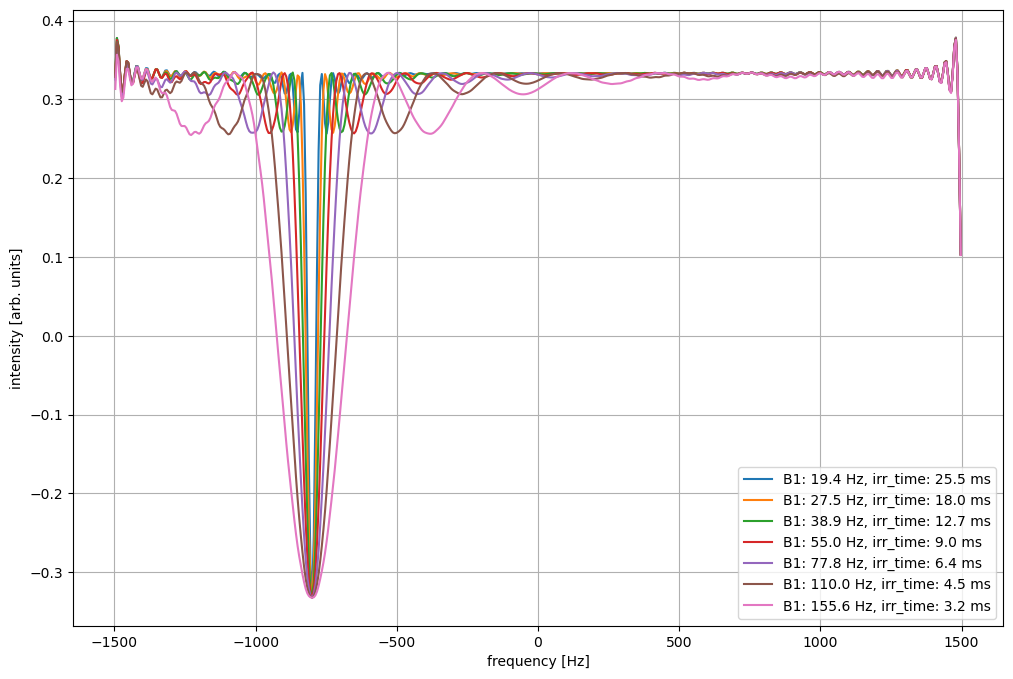

In [77]:
irr_B1_strengths = [19.4, 27.5, 38.9, 55.0, 77.8, 110.0, 155.6]
irr_times = [0.0255, 0.018, 0.0127, 0.009, 0.0064, 0.0045, 0.0032]
plt.figure(figsize=(12, 8))

for i, B1 in enumerate(irr_B1_strengths):
    COdimension = DimensionParams(
        points = 175,
        spectral_width = 3000,
        irradiation_time = irr_times[i],
        irradiation_B1_strength = B1,
    )
    time_axis, profile, profile_full = get_profile_from_peaks(Ndimension, COdimension,
        peak1,
        fid_zero_filling = fid_zero_filling,
        noise_factor = noise_factor, 
        spectrum_zero_filling = spectrum_zero_filling, 
        sigma = sigma,
        weighting_flag = False,
        plot_flag = False,
        )
    plt.plot(time_axis, profile.real, label=f'B1: {B1} Hz, irr_time: {COdimension.irradiation_time*1000} ms')

plt.xlabel('frequency [Hz]')
plt.ylabel('intensity [arb. units]')
plt.legend()
plt.grid(True)
plt.show()

Width at half-height

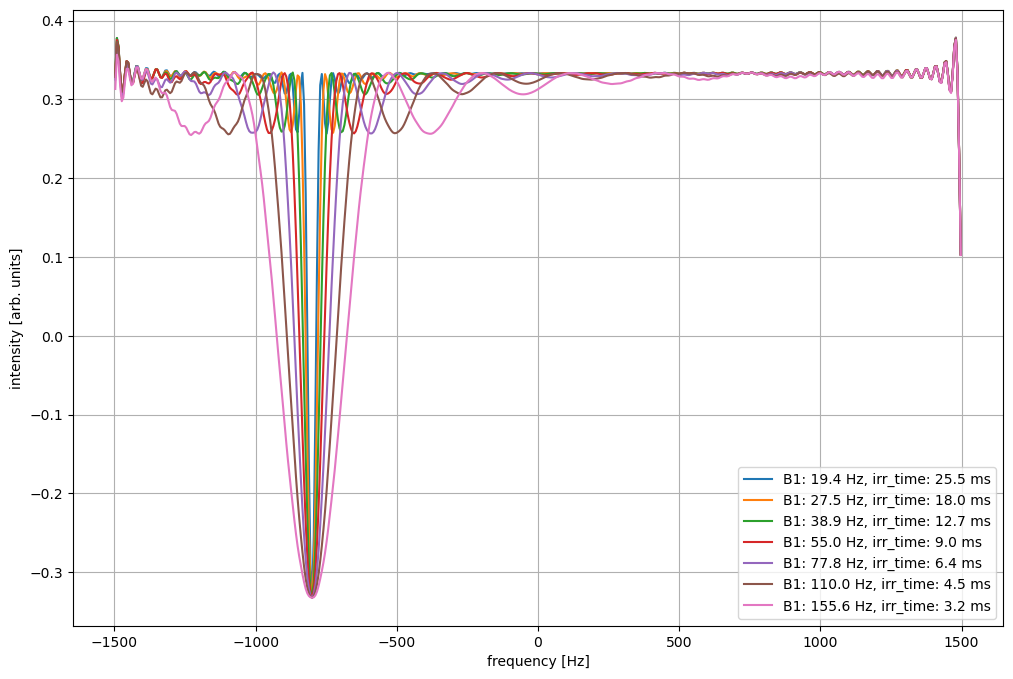

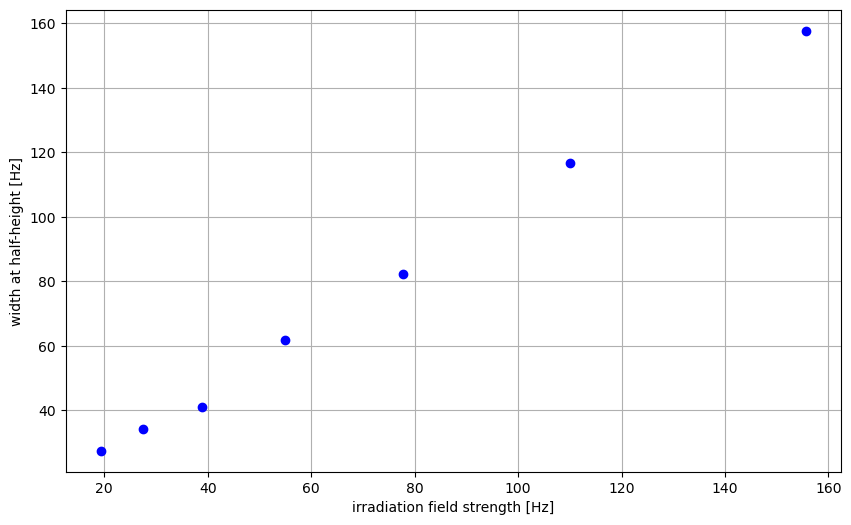

In [78]:
irr_B1_strengths = [19.4, 27.5, 38.9, 55.0, 77.8, 110.0, 155.6]
irr_times = [0.0255, 0.018, 0.0127, 0.009, 0.0064, 0.0045, 0.0032]

widths_Hz = []

plt.figure(figsize=(12, 8))

for i, B1 in enumerate(irr_B1_strengths):
    COdimension = DimensionParams(
        points = 175,
        spectral_width = 3000,
        irradiation_time = irr_times[i],
        irradiation_B1_strength = B1,
    )
    time_axis, profile, profile_full = get_profile_from_peaks(Ndimension, COdimension,
        peak1,
        fid_zero_filling = fid_zero_filling,
        noise_factor = noise_factor, 
        spectrum_zero_filling = spectrum_zero_filling, 
        sigma = sigma,
        weighting_flag = False,
        plot_flag = False,
        )
    plt.plot(time_axis, profile.real, label=f'B1: {B1} Hz, irr_time: {COdimension.irradiation_time*1000} ms')

    min_val = min(profile)
    max_val = max(profile)
    min_index = list(profile).index(min_val)
    baseline = max_val
    half_height = min_val + (baseline - min_val) / 2
    for j in range(len(profile)):
        if profile[min_index - j] > half_height:
            width_half = j
            break
    width = width_half*2
    widths_Hz.append(width*COdimension.spectral_width/(COdimension.points*fid_zero_filling))

plt.xlabel('frequency [Hz]')
plt.ylabel('intensity [arb. units]')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(irr_B1_strengths, widths_Hz, 'o-', linewidth=0, color = 'b')
plt.xlabel('irradiation field strength [Hz]')
plt.ylabel('width at half-height [Hz]')
plt.grid(True)
plt.show()

Different irradiation field strengths (with the same irradiation duration)

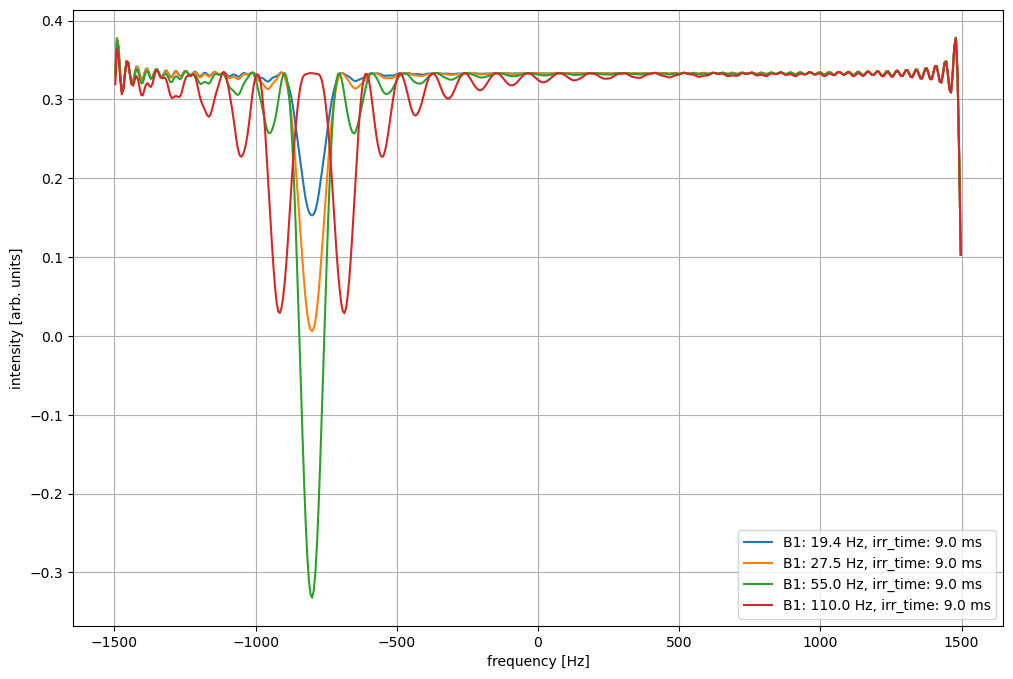

In [79]:
irr_B1_strengths = [19.4, 27.5, 55.0, 110.0]
plt.figure(figsize=(12, 8))

for i, B1 in enumerate(irr_B1_strengths):
    COdimension = DimensionParams(
        points = 175,
        spectral_width = 3000,
        irradiation_time = 0.009,
        irradiation_B1_strength = B1,
    )
    time_axis, profile, profile_full = get_profile_from_peaks(Ndimension, COdimension,
        peak1,
        fid_zero_filling = fid_zero_filling,
        noise_factor = noise_factor, 
        spectrum_zero_filling = spectrum_zero_filling, 
        sigma = sigma,
        weighting_flag = False,
        plot_flag = False,
        )
    plt.plot(time_axis, profile.real, label=f'B1: {B1} Hz, irr_time: {COdimension.irradiation_time*1000} ms')
plt.xlabel('frequency [Hz]')
plt.ylabel('intensity [arb. units]')
plt.legend()
plt.grid(True)
plt.show()

Influence of irradiation duration (for the same irradiation field strength)

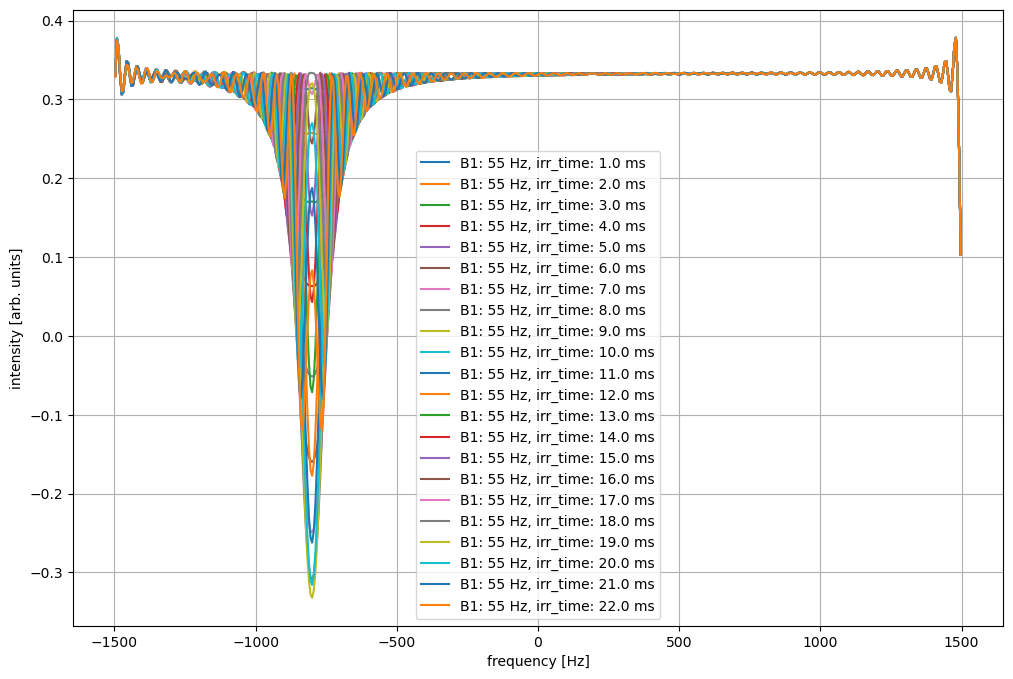

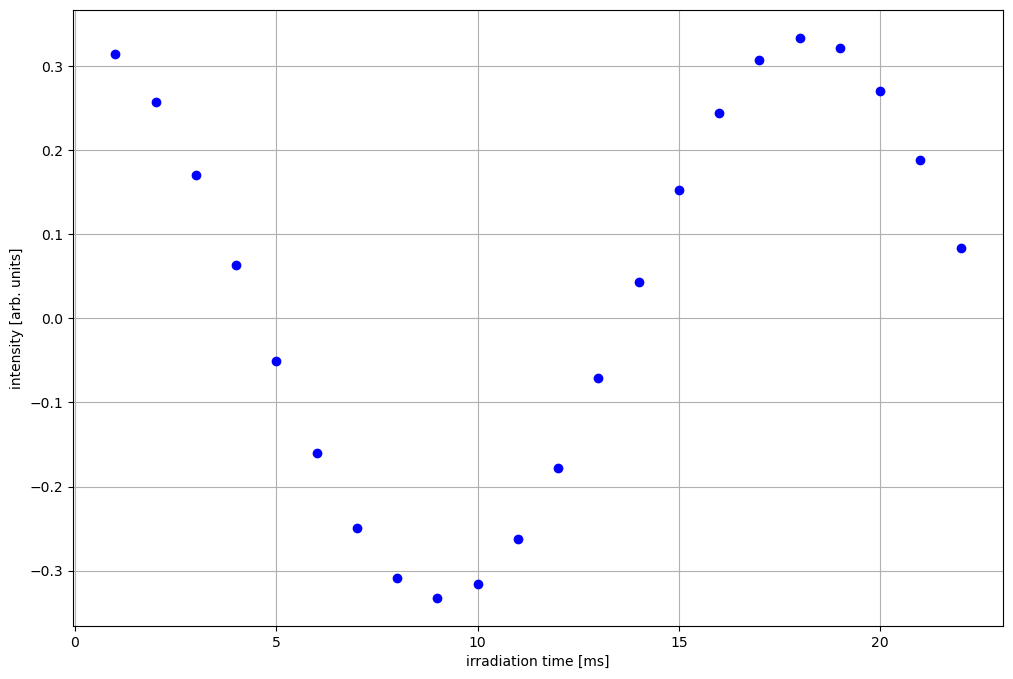

In [80]:
irr_times = [0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009,
    0.010, 0.011, 0.012, 0.013, 0.014, 0.015, 0.016, 0.017, 0.018, 
    0.019, 0.020, 0.021, 0.022]
#irr_times = [0.003, 0.006, 0.009, 0.012, 0.018]

profiles = []
min_intensities = []

plt.figure(figsize=(12, 8))
for i, irr_time in enumerate(irr_times):
    COdimension = DimensionParams(
        points = 175,
        spectral_width = 3000,
        irradiation_time = irr_time,
        irradiation_B1_strength = 55,
    )
    time_axis, profile, profile_full = get_profile_from_peaks(Ndimension, COdimension,
        peak1,
        fid_zero_filling = fid_zero_filling,
        noise_factor = noise_factor, 
        spectrum_zero_filling = spectrum_zero_filling, 
        sigma = sigma,
        weighting_flag = False,
        plot_flag = False,
        )
    profiles.append(profile.real)
    min_intensities.append(min(profile.real))

    plt.plot(time_axis, profile.real, label=f'B1: {COdimension.irradiation_B1_strength} Hz, irr_time: {COdimension.irradiation_time*1000} ms')
plt.xlabel('frequency [Hz]')
plt.ylabel('intensity [arb. units]')
plt.legend()
plt.grid(True)
plt.show()

lowest_minimum = min(min_intensities)
profile_with_lowest_minimum = profiles[min_intensities.index(lowest_minimum)]
lowest_minimum_index = np.argmin(profile_with_lowest_minimum)
min_intensities = [profile[lowest_minimum_index] for profile in profiles]


irr_times_ms = [irr_time * 1000 for irr_time in irr_times]
plt.figure(figsize = (12, 8))
plt.plot(irr_times_ms, min_intensities, 'o-', linewidth = 0, color = 'b')
plt.xlabel('irradiation time [ms]')
plt.ylabel('intensity [arb. units]')
plt.grid(True)
plt.show()